# Methoden en Technieken -- Blok 1b

## Datapunt Opdracht
In deze opdracht worden de volgende leeruitkomsten getoetst, relevante termen zijn **dik** gedrukt:
- A2: Je stelt voor een AI-oplossing juridische, ethische, organisatorische, **functionele en
technische requirements** op.
- B1: Je **verkent en prepareert een dataset voor het trainen en testen van een AI-model** en
kan de voor- en nadelen van het gebruik van een bestaande dataset onderbouwen, rekening
houdend met technische en ethische randvoorwaarden.
- B2: Je **stelt op basis van requirements en data een geschikte architectuur voor een AI-
oplossing op en selecteert daarvoor passende AI-technieken gebruik makend van bijvoorbeeld
machine learning, deep learning**, kennisrepresentatie, computer vision en natural language
processing.
- B3: Je **ontwikkelt een nieuw** of voorgetraind **AI-model** volgens een iteratief en systematisch
proces.
- C2: **Je evalueert en beoordeelt de kwaliteit van een AI-model aan de hand van kwaliteitscriteria die in het vakgebied erkend worden** zoals robustness, **performance**, scalability,
**explainability**, **model complexity** en resource demand.


<hr>

- Dit is een individuele opdracht. Het is toegestaan met elkaar de opdracht te bespreken, maar iedereen schrijft zijn/haar eigen code en antwoorden. 
- Mocht je code van het internet hebben overgenomen/aangepast, vermeld dan de bron in het commentaar.
- Mocht je naar een bron verwijzen voor jouw argumentatie, vermeld dan de bron *en* copy-paste de specifieke uitspraak uit de bron waar je het argument op baseert. 
- Het gebruik van generatieve AI (Chat-GPT, etc...) is *alleen* toegestaan bij de voorbereiding op de opdracht. Denk hierbij aan activiteiten zoals brainstormen, of het maken van een plan. Het is niet toegestaan code of tekst van generative AI over te nemen. (Level 2 van de AI Assessment Scale)



In [1]:
import os
import sys

# Stel PyTorch in als backend voor Keras
os.environ["KERAS_BACKEND"] = "torch"

import keras
import torch
import numpy as np
import matplotlib.pyplot as plt

print("Python:", sys.executable)
print("Keras:", keras.__version__)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Keras backend:", keras.backend.backend())

Python: c:\Dev\Wander - ML Assignment\.venv\Scripts\python.exe
Keras: 3.15.1
PyTorch: 2.14.1+cpu
NumPy: 2.5.4
Keras backend: torch


## Data

In deze opdracht werken we met gesimuleerde data, deze wordt hier aangemaakt. We gaan hier wel van uit dat dit de volledige data is, het is niet toegestaan extra trekkingen te doen.

In [2]:
# Verband tussen x en y
def f(x):
    return (+ 1.5*np.tanh(20*x - 6)  
            - 1.0*np.tanh(10*x - 4)
            - 1.0*np.tanh( 8*x - 4)
            + 0.5*np.tanh(15*x - 12))


In [3]:
# Trek data
np.random.seed(42)
noise = np.random.normal(scale = 0.1, size = 1000).reshape(-1,1)
xdat = np.random.uniform(0,1, size=1000).reshape(-1,1)
ydat = f(xdat) + noise

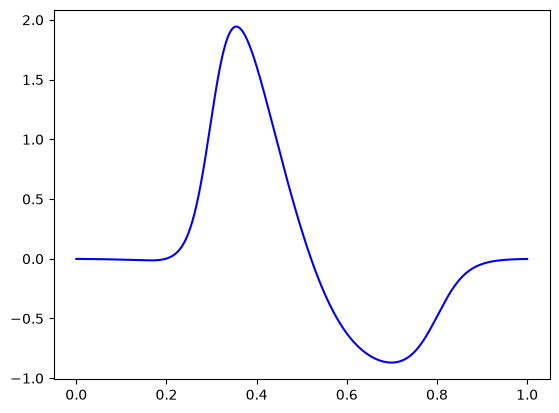

In [4]:
# Plot echt verband
xplot = np.linspace(0,1,10001)
yplot = f(xplot)
plt.plot(xplot, yplot, 'b-')
plt.show()

In deze opdracht is het de bedoeling om middels een neuraal netwerk de data $(xdat,ydat)$ die hierboven werdt gegeven te benaderen. Het uiteindelijke model behoort,
* de data / de functie $f$ zo goed mogelijk te benaderen, en
* zo simpel mogelijk te zijn (interpreteerbaarheid van model).


# Voorwoord
Ik ga me me in deze opdracht vooral focussen op leeruitkomst B2. Dit is de leeruitkomst die ik in de vorige opdracht onder niveau heb behaald en daarom wil ik me in deze opdracht hier graag in verbeteren en focussen

*B2: Je stelt op basis van requirements en data een geschikte architectuur voor een AI-
oplossing op en selecteert daarvoor passende AI-technieken gebruik makend van bijvoorbeeld
machine learning, deep learning, kennisrepresentatie, computer vision en natural language
processing.*


# Deel 1

## 1ste indruk

Om deze opdracht te tackelen, moet ik eerst goed kijken naar wat er nou eigenlijk gevraagd wordt. Voor zover ik het nu begrijp, gaan we een tamelijk klein neuraal netwerk (NN) maken om een functie met vier tanh-termen te benaderen. Mijn wiskunde is op zich wel prima, maar het is toch weer even graven.

We krijgen 1.000 willekeurig gesimuleerde observaties, bestaande uit een invoervariabele ($x$) en een bijbehorende uitvoervariabele ($y$). De oorspronkelijke functie wordt daarbij 'vervuild' met normaal verdeelde ruis met een standaardafwijking van 0,1. We mogen ook geen extra observaties genereren.

Het doel is om met een neuraal netwerk het onderliggende verband zo nauwkeurig mogelijk te benaderen. Tegelijkertijd moet het model eenvoudig blijven, zonder al te veel poespas.

Om de opdracht uit te voeren, ga ik de methode gebruiken die we in les 6 hebben geleerd. Ik vind het namelijk lastig om te bepalen waar ik moet beginnen, dus ik ga vooral kijken naar de stappen die we tijdens die les hebben doorlopen.

Daarom begin ik met het analyseren van de eigenschappen van de functie en de dataset, voordat ik een netwerkstructuur ga kiezen en onderbouwen. Op deze manier kan ik volgens mij ook beter de juiste requirements opstellen en mijn keuzes onderbouwen.

## De wiskunde en het probleem

De dataset bestaat uit één numerieke invoervariabele en één continue uitvoervariabele. Dat betekent dat we deze opdracht kunnen beschouwen als een *supervised regressieprobleem*. Het doel is om een benadering $\hat{f}(x)$ te vinden van de oorspronkelijke functie $f(x)$, zoals we ook in les 2 hebben behandeld.

In les 3 is behandeld dat bij regressie met de Mean Squared Error (MSE) de optimale voorspellingsfunctie overeenkomt met de voorwaardelijke verwachtingswaarde:

$$
\hat{f}_{\mathrm{opt}}(x)=E[Y\mid X=x]
$$

De observaties worden gegenereerd volgens:

$$
Y=f(X)+\varepsilon
$$

Hierbij is $\varepsilon$ de toegevoegde normaal verdeelde ruis. Omdat deze ruis onafhankelijk van $X$ wordt gegenereerd en een verwachtingswaarde van nul heeft, geldt:

$$
E[Y\mid X=x]=f(x)
$$

Wanneer we de verwachte MSE zo klein mogelijk maken, zoeken we dus naar een voorspelling die zo dicht mogelijk bij de oorspronkelijke functie ligt. Daarom lijkt MSE mij een geschikte kwaliteitsmaat voor deze opdracht.

De ruis heeft een standaardafwijking van 0,1. De variantie bedraagt daarmee:

$$
\sigma^2=0.1^2=0.01
$$

Dit betekent dat zelfs een model dat de oorspronkelijke functie exact voorspelt, op nieuwe observaties gemiddeld nog een MSE van 0,01 zal behalen door de toegevoegde ruis. Dit is de theoretisch minimaal haalbare verwachte MSE, maar geen harde ondergrens voor een eindige dataset. Door toeval kan de gemeten MSE namelijk lager of hoger uitvallen.

Ik wil deze waarde daarom gebruiken als referentiepunt bij het beoordelen van de nauwkeurigheid van mijn model.

**Bronnen:**
- HvA. (2026). *Blok 1 – Les 2* [Lesmateriaal]. Supervised learning en regressie.
- HvA. (2026). *Blok 1 – Les 3* [Lesmateriaal]. Regressie en Mean Squared Error.

### Keuze van de netwerkarchitectuur

Omdat het verband in de functie niet-lineair is en we specifiek een neuraal netwerk moeten gebruiken, lijkt het me logisch om een *feedforward neural network* te kiezen.

In les 10 is behandeld hoe feedforward neurale netwerken worden opgebouwd uit opeenvolgende lagen, waarbij gewichten, biases en activatiefuncties bepalen welke transformaties het netwerk kan uitvoeren.

Aangezien de functie die we willen benaderen uit vier tanh-termen bestaat, lijkt het me logisch om ook vier neuronen met een tanh-activatiefunctie in één verborgen laag te gebruiken. Vervolgens kunnen we onderzoeken welke gewichten en biases het beste werken.

De oorspronkelijke functie bestaat uit vier hyperbolische tangensfuncties. Deze hebben allemaal dezelfde algemene vorm:

$$
a_i\tanh(w_ix+b_i)
$$

Hierbij is:

- $w_i$: het inputgewicht dat bepaalt hoe snel de tanh-functie verandert.
- $b_i$: de bias die de horizontale positie van de overgang beïnvloedt.
- $a_i$: het outputgewicht waarmee de bijdrage van de tanh-functie wordt vermenigvuldigd.

De volledige functie is dus een gewogen som van vier tanh-functies:

$$
f(x)=\sum_{i=1}^{4}a_i\tanh(w_ix+b_i)
$$

Een netwerk met vier verborgen neuronen en een lineaire output heeft de algemene vorm:

$$
\hat{f}(x)=c+\sum_{i=1}^{4}a_i\tanh(w_ix+b_i)
$$

Hierbij is $c$ de bias van de outputlaag.

Het netwerk zou er dan ongeveer zo uitzien:

- 1 input ($x$).
- 1 verborgen laag met 4 neuronen en tanh-activatiefuncties.
- 1 outputneuron met een lineaire activatiefunctie ($\hat{y}$).

Het netwerk heeft vier inputgewichten, vier biases in de verborgen laag, vier outputgewichten en één outputbias. Daarmee kom ik op:

$$
4+4+4+1=13
$$

trainbare parameters.

De oorspronkelijke functie kan met deze architectuur theoretisch exact worden gerepresenteerd door de juiste gewichten en biases in te stellen. De outputbias kan daarbij op nul worden gezet.

We moeten echter wel in ons achterhoofd houden dat we op zoek zijn naar een afweging tussen eenvoud en nauwkeurigheid. Het is dus mogelijk dat een kleiner netwerk de functie ook voldoende nauwkeurig benadert, zelfs als het de oorspronkelijke wiskundige vorm niet exact kan reproduceren. Een groter netwerk kan misschien nauwkeuriger voorspellen, maar heeft ook meer parameters. Daar ligt een interessante keuze.

**Bron:**
- HvA. (2026). *Blok 1 – Les 10: Neurale Netwerken* [Lesmateriaal]. Netwerkarchitecturen, gewichten, biases en activatiefuncties.

### Beperkingen van mijn architectuurkeuze

Hoewel een netwerk met vier tanh-neuronen de oorspronkelijke functie theoretisch exact kan representeren, betekent dit niet dat het tijdens de training ook de juiste parameters zal vinden.

Een belangrijk nadeel van neurale netwerken is dat de training afhankelijk kan zijn van de willekeurige initialisatie van de gewichten. Verschillende startwaarden kunnen daardoor tot verschillende resultaten leiden. Glorot en Bengio (2010) bespreken hoe de initialisatie van gewichten invloed heeft op het trainen van neurale netwerken.

Ook kan de training tijdelijk op een plateau blijven steken, waardoor de MSE nauwelijks meer daalt terwijl het model nog niet optimaal is. Glorot en Bengio (2010) beschrijven onder andere hoe verzadiging van activatiefuncties het leerproces kan vertragen. Hun onderzoek richt zich vooral op diepere netwerken, maar laat zien waarom het belangrijk is om het trainingsverloop kritisch te bekijken.

Daarnaast zijn de geleerde gewichten niet altijd eenvoudig te interpreteren. Zelfs wanneer het netwerk de oorspronkelijke functie goed benadert, hoeven de afzonderlijke tanh-neuronen niet één-op-één overeen te komen met de vier oorspronkelijke termen.

Dit komt onder andere doordat neuronen van volgorde kunnen wisselen zonder dat de voorspelling verandert. Ook geldt dat $\tanh(-z)=-\tanh(z)$, waardoor verschillende combinaties van tekens bij de gewichten dezelfde bijdrage kunnen leveren.

Ik wil daarom tijdens mijn experimenten niet alleen naar de laagste MSE kijken, maar ook onderzoeken hoe stabiel de training is en of de geleerde functie daadwerkelijk overeenkomt met de oorspronkelijke functie.

In deel 3 onderzoek ik de invloed van de trainingsduur en verschillende initialisaties. In deel 5 vergelijk ik de geleerde gewichten met de oorspronkelijke functieparameters.

**Bron:**
- Glorot, X., & Bengio, Y. (2010). *Understanding the difficulty of training deep feedforward neural networks*. Proceedings of the Thirteenth International Conference on Artificial Intelligence and Statistics, 9, 249–256. https://proceedings.mlr.press/v9/glorot10a.html

Voor nu vind ik het even genoeg en heb ik een eerste richting voor deze opdracht. Ik heb een idee van welke architectuur geschikt kan zijn, welke beperkingen ik moet meenemen en wat ik tijdens het trainen en evalueren wil onderzoeken.


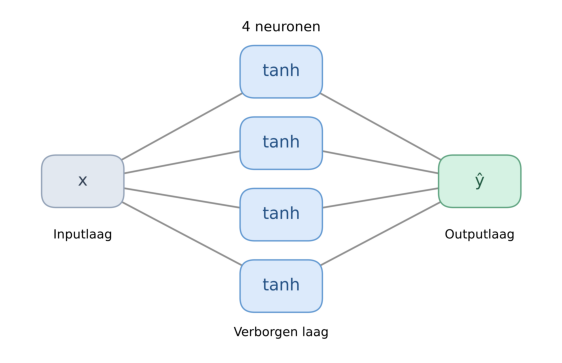

In [5]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

fig = mpimg.imread("neurale_netwerk_architectuur.png")

plt.figure(figsize=(7, 5))
plt.imshow(fig)
plt.axis("off")
plt.show()


## *Requirements*

Op basis van mijn eerdere redenering heb ik de volgende requirements opgesteld. Hierbij maak ik onderscheid tussen functionele requirements, die ik rechtstreeks uit de deelvragen van de opdracht heb afgeleid, en technische requirements, die voortkomen uit mijn eerdere analyse van de functie en de behandelde lesstof.

### Functionele requirements

| Nr | Requirement | Verificatie |
|---|---|---|
| F1| Het model moet voor iedere invoerwaarde $x$ binnen het interval $[0,1]$ één continue voorspelling $\hat{y}$ kunnen produceren. | Voorspellingen genereren over het volledige interval. |
| F2 | Het model moet het onderliggende niet-lineaire verband $f(x)$ kunnen benaderen, zonder de toegevoegde ruis als onderdeel van de functie te beschouwen. | De voorspelde functie vergelijken met de oorspronkelijke, ruisvrije functie. |
| F3 | De voorspelde functie moet visueel vergeleken kunnen worden met de oorspronkelijke functie. | Beide functies in dezelfde grafiek weergeven. |
| F4 | De geleerde gewichten en biases moeten inzichtelijk zijn, zodat onderzocht kan worden in hoeverre het model de oorspronkelijke functie heeft gereconstrueerd. | De modelparameters uitlezen en vergelijken met de oorspronkelijke parameters. |

### Technische requirements

| Nr | Requirement | Verificatie |
|---|---|---|
| T1 | Het netwerk moet bestaan uit één inputnode, minimaal één verborgen laag met niet-lineaire activatiefuncties en één lineaire outputnode. | De netwerkarchitectuur controleren. |
| T2 | De referentiearchitectuur moet de oorspronkelijke functie met vier tanh-termen exact kunnen representeren. | Aantonen dat de oorspronkelijke parameters in het netwerk kunnen worden ingevuld. |
| T3 | De referentiearchitectuur mag maximaal 13 trainbare parameters bevatten. | Het aantal parameters berekenen en controleren. |
| T4 | Het model moet worden getraind met een loss-functie die geschikt is voor continue regressie met normaal verdeelde ruis. | De gekozen loss-functie wiskundig onderbouwen. |
| T5 | Training, modelselectie en definitieve evaluatie moeten plaatsvinden op gescheiden datasets, zonder datalekken. | De datasplitsing en preprocessing controleren. |
| T6 | De modelprestaties moeten kwantitatief worden beoordeeld en vergeleken met een nulmodel. | Dezelfde prestatiemaat berekenen voor beide modellen. |

### Kwaliteitseisen en acceptatiecriteria

| Nr | Requirement | Criterium |
|---|---|---|
| K1 | Het model moet beter voorspellen dan een eenvoudig nulmodel. | De validatie-MSE is lager dan die van het nulmodel. |
| K2 | Het model moet de oorspronkelijke functie zo nauwkeurig mogelijk benaderen. | De validatie-MSE wordt beoordeeld ten opzichte van de theoretische ruisvariantie van $0.01$. |
| K3 | Het model moet zo eenvoudig mogelijk zijn zonder onacceptabel prestatieverlies. | Wanneer de validatie-MSE van een eenvoudiger model binnen 5% van de laagste validatie-MSE ligt, krijgt het model met minder parameters de voorkeur. |
| K4 | Het model moet generaliseren naar ongeziene observaties. | De testprestaties worden na modelselectie vergeleken met de validatieresultaten. |
| K5 | Het model moet interpreteerbaar zijn. | De afzonderlijke tanh-bijdragen en de geleerde parameters kunnen worden geanalyseerd. |

De grens van **5%** bij kwaliteitseis K3 is een willekeurige ontwerpkeuze (Dit zou een steakholder vraag zijn die ik nu zelf invul). Deze gebruik ik om vooraf vast te leggen hoeveel nauwkeurigheid ik bereid ben in te leveren voor een eenvoudiger model.

De ruis heeft een standaardafwijking van $0.1$, waardoor de theoretische ruisvariantie gelijk is aan:

$$\sigma^2 = 0.1^2 = 0.01$$

Deze waarde gebruik ik bij Kwaliteitseis K2 als theoretisch referentiepunt en niet als harde foutgrens.

De eisen technische eisen T2 en T3 gelden specifiek voor de **referentiearchitectuur** met vier tanh-neuronen. Bij het onderzoeken van kleinere architecturen kan hiervan worden afgeweken, zolang deze modellen aan de functionele eisen en acceptatiecriteria voldoen.


# Deel 2

## *Datasplitsing*

Voordat ik de dataset ga onderzoeken gaan we eerst splitten. Hiermee wil ik voorkomen dat informatie uit de testdata onbewust invloed heeft op mijn modelkeuzes en training proces.

Ik kies voor een verdeling van 70% training, 15% validatie en 15% test. Dit betekent dat ik 700 observaties gebruik voor het trainen, 150 voor het vergelijken van modellen en 150 voor de uiteindelijke evaluatie. Dit lijkt mij een mooie verdeling. vooral om genoeg data te hebben voor het trainen van het model.

Voor de data-exploratie gebruik ik vanaf nu alleen de trainingsdata. De validatieset bewaar ik voor het vergelijken van de verschillende netwerkarchitecturen en de testset gebruik ik pas wanneer het definitieve model is gekozen.

In [6]:
from sklearn.model_selection import train_test_split

# Eerst 15% apart houden voor de testset
x_trainval, x_test, y_trainval, y_test = train_test_split(
    xdat, ydat,
    test_size=0.15,
    random_state=42
)

# De resterende 85% verdelen in training en validatie
x_train, x_val, y_train, y_val = train_test_split(
    x_trainval, y_trainval,
    test_size=15/85,
    random_state=42
)

# Controle
print(f"Training:  {len(x_train)} observaties")
print(f"Validatie: {len(x_val)} observaties")
print(f"Test:      {len(x_test)} observaties")

Training:  700 observaties
Validatie: 150 observaties
Test:      150 observaties


We kunnen meteen controleren of de inputwaarden van de trainingsdata inderdaad tussen 0 en 1 liggen.

In [7]:
import pandas as pd

train_df = pd.DataFrame({
    "x": x_train.ravel(),
    "y": y_train.ravel()
})

display(train_df.describe())


,x,y
count,700.000000,700.000000
mean,0.506831,0.059668
std,0.286960,0.738269
min,0.004940,-1.063114
25%,0.254601,-0.450960
50%,0.518164,-0.045218
75%,0.755494,0.190813
max,0.998348,2.087349


De gemiddelde waarde van $x$ is ongeveer 0,507 en de standaardafwijking is 0,287. Dit komt goed overeen met wat ik verwacht bij een uniforme verdeling tussen 0 en 1. Ook liggen de minimale en maximale waarden dicht bij de grenzen van dit interval dus alles klopt en er gebeurt niks geks.

Bij $y$ zie ik een gemiddelde van ongeveer 0,060 en een standaardafwijking van 0,738. Deze spreiding is aanzienlijk groter dan de standaardafwijking van de toegevoegde ruis (0,1). Ik vermoed daarom dat een groot deel van de variatie wordt veroorzaakt door de oorspronkelijke functie.

Op basis van deze statistieken zie ik voorlopig geen opvallende afwijkingen. Wel zeggen deze getallen nog weinig over de vorm van het verband tussen $x$ en $y$. Daarom wil ik de trainingsdata nu visualiseren en vergelijken met de oorspronkelijke functie.

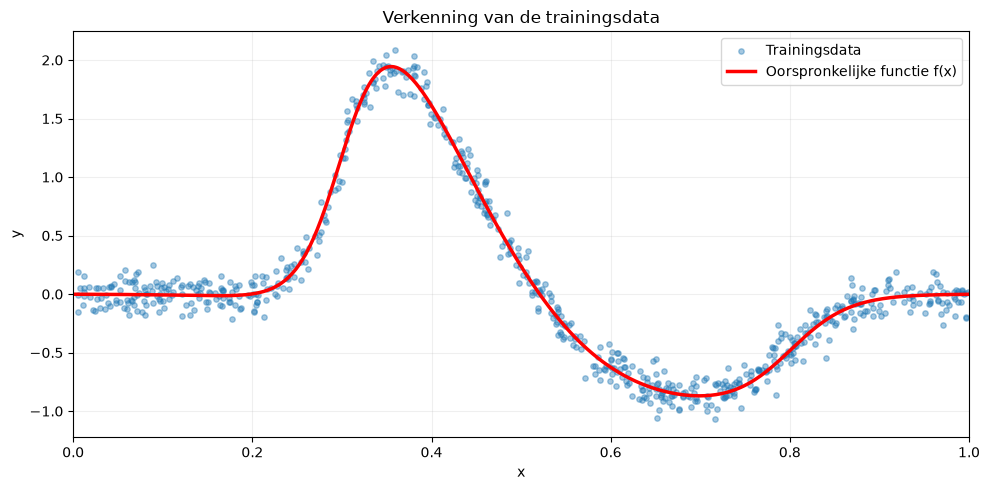

In [8]:
import numpy as np
import matplotlib.pyplot as plt

x_plot = np.linspace(0, 1, 500).reshape(-1, 1)

plt.figure(figsize=(10, 5))

plt.scatter(
    x_train,
    y_train,
    alpha=0.4,
    s=15,
    label="Trainingsdata"
)

plt.plot(
    x_plot,
    f(x_plot),
    color="red",
    linewidth=2.5,
    label="Oorspronkelijke functie f(x)"
)

plt.title("Verkenning van de trainingsdata")
plt.xlabel("x")
plt.ylabel("y")
plt.xlim(0, 1)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## Analyse van de data

Als ik de scatterplot vergelijk met de oorspronkelijke functie $f(x)$ die we in Deel 1 hebben bekeken, zie ik duidelijk dezelfde vorm terug. Ondanks de toegevoegde ruis zijn de verschillende overgangen en de relatief vlakke stukken goed herkenbaar.

Wat mij vooral opvalt, is dat de ruis het onderliggende verband niet volledig verstoort. De observaties liggen redelijk dicht rondom een herkenbaar patroon. De spreiding lijkt bovendien over het hele interval ongeveer gelijk te blijven. Dat past bij de normaal verdeelde ruis met een vaste standaardafwijking van 0,1 waarmee de dataset is gegenereerd. Op basis van alleen deze grafiek kan ik dat echter nog niet met zekerheid vaststellen.

## Data preparatie

Wat betreft data prep zie ik voorlopig weinig aanleiding om de data uitgebreid te bewerken. De invoervariabele $x$ ligt al tussen 0 en 1, waardoor aanvullende normalisatie niet direct noodzakelijk lijkt. Ook de outputwaarden hebben geen extreem groot bereik.

Wel moet ik rekening houden met de tanh-activatiefunctie die ik wil gebruiken. In les 12 en 14 is het *vanishing gradient*-probleem behandeld. Bij tanh kunnen de gradiënten erg klein worden wanneer de neuronen verzadigen, waardoor het trainen lastiger kan verlopen. Dit lijkt me daarom iets om tijdens het trainen in de gaten te houden.

In mijn geval is dit niet direct een reden om de data te schalen. De vlakke delen van tanh zijn namelijk juist onderdeel van de functie die ik wil benaderen. Omdat $x$ al tussen 0 en 1 ligt, wil ik eerst onderzoeken hoe het netwerk zonder aanvullende schaling presteert.

Verder zie ik geen duidelijke uitschieters die aanleiding geven om observaties te verwijderen. Omdat de ruis bewust onderdeel is van de dataset, lijkt het me ook niet verstandig om de data vooraf glad te strijken of te filteren. Daarmee zou ik mogelijk juist informatie over het oorspronkelijke verband veranderen.

## Model keuze

De grafiek ondersteunt mijn eerdere keuze voor een klein feedforward neuraal netwerk met tanh-activatiefuncties. De verschillende stijgingen, dalingen en vlakke gebieden lijken goed aan te sluiten bij het gedrag van een combinatie van tanh-functies.

Omdat we uit de wiskundige definitie weten dat $f(x)$ uit vier tanh-termen bestaat, blijft een verborgen laag met vier tanh-neuronen voor mij een logisch uitgangspunt. Met deze architectuur kan het netwerk de oorspronkelijke functie in theorie exact representeren. De vraag is alleen of het netwerk deze functie ook daadwerkelijk uit de observaties met ruis kan leren.

Tegelijkertijd zie ik in de grafiek een relatief eenvoudig en vloeiend patroon. Daarom wil ik niet op voorhand aannemen dat vier neuronen ook noodzakelijk zijn voor een voldoende nauwkeurige benadering. Ik wil later kleinere architecturen vergelijken om te onderzoeken hoeveel complexiteit we daadwerkelijk nodig hebben.

**Conclusie**

De data-exploratie bevestigt grotendeels mijn verwachtingen uit Deel 1. Het niet-lineaire verband is duidelijk zichtbaar en lijkt sterk op de oorspronkelijke functie. De ruis maakt de observaties minder nauwkeurig, maar het onderliggende patroon blijft goed herkenbaar.

Voorlopig zie ik daarom geen reden om uitgebreide preprocessing toe te passen. Ik wil de oorspronkelijke observaties behouden en beginnen met een eenvoudig netwerk met vier tanh-neuronen als referentiearchitectuur. Vervolgens kan ik onderzoeken of een kleiner netwerk vergelijkbare prestaties behaalt.

De uiteindelijke modelkeuze wil ik baseren op de validatie-MSE en het aantal trainbare parameters, zoals ik eerder in mijn requirements heb vastgelegd.
In de scatterplot zie ik duidelijk dat er een niet-lineair verband bestaat tussen $x$ en $y$.

Tot ongeveer $x=0.2$ blijft de output redelijk constant rond 0. Daarna stijgt deze sterk en bereikt rond $x=0.35$ een piek van ongeveer 2. Vervolgens daalt de output en ontstaat rond $x=0.65$ tot $0.70$ een dal van ongeveer -0.9. Richting $x=1$ stijgt de output weer naar ongeveer 0.

De observaties liggen redelijk dicht bij dit patroon, ondanks de toegevoegde ruis. Op het eerste gezicht lijkt de spreiding rondom het verband ongeveer gelijkmatig over het interval.

Dit bevestigt mijn eerdere verwachting dat we een niet-lineair model nodig hebben. Vooral de sterke stijging en daling lijken me interessant, omdat het netwerk deze overgangen goed moet kunnen leren.

Voorlopig zie ik geen duidelijke uitschieters die aanleiding geven om observaties te verwijderen.


### Analyse van de trainingsdata

De scatterplot laat een duidelijk niet-lineair verband zien. Rond (x=0,35) ligt een piek van ongeveer 2, gevolgd door een minimum rond (x=0,7) van ongeveer −0,9. Richting (x=1) nadert de output opnieuw nul.

De observaties liggen relatief dicht rondom dit patroon. De spreiding lijkt over het interval ongeveer constant, wat aansluit bij de toegevoegde ruis met vaste standaardafwijking. Dit is een visuele aanwijzing, geen statistische bevestiging van homoscedasticiteit.

### Data preparatie

Ik voer geen aanvullende schaling uit. De invoer ligt al binnen ([0,1]) en het bereik van de uitvoer is beperkt. Bovendien wil ik eerst onderzoeken hoe het netwerk met de oorspronkelijke waarden presteert.

Bij tanh-activaties kunnen verzadigde neuronen kleine gradiënten veroorzaken, waardoor training vertraagt. Daarom controleer ik tijdens de experimenten of de trainings- en validatie-MSE voldoende blijven dalen.

Ik zie in de scatterplot geen duidelijke aanleiding om observaties te verwijderen. De zichtbare spreiding past bij de ruis die bewust aan de data is toegevoegd.

### Modelkeuze

De grafiek ondersteunt mijn eerdere keuze voor een klein feedforward neuraal netwerk met tanh-activatiefuncties. De verschillende stijgingen, dalingen en vlakke gebieden lijken goed aan te sluiten bij het gedrag van een combinatie van tanh-functies.

Omdat we uit de wiskundige definitie weten dat $f(x)$ uit vier tanh-termen bestaat, blijft een verborgen laag met vier tanh-neuronen voor mij een logisch uitgangspunt. Met deze architectuur kan het netwerk de oorspronkelijke functie in theorie exact representeren. De vraag is alleen of het netwerk deze functie ook daadwerkelijk uit de observaties met ruis kan leren.

Tegelijkertijd zie ik in de grafiek een relatief eenvoudig en vloeiend patroon. Daarom wil ik niet op voorhand aannemen dat vier neuronen ook noodzakelijk zijn voor een voldoende nauwkeurige benadering. Ik wil later kleinere architecturen vergelijken om te onderzoeken hoeveel complexiteit we daadwerkelijk nodig hebben.

## *Conclusie*

De data-exploratie bevestigt grotendeels mijn verwachtingen uit Deel 1. Het niet-lineaire verband is duidelijk zichtbaar en lijkt sterk op de oorspronkelijke functie. De ruis maakt de observaties minder nauwkeurig, maar het onderliggende patroon blijft goed herkenbaar.

Voorlopig zie ik daarom geen reden om uberhaupt data preparatie uittevoeren. Ik wil de oorspronkelijke observaties behouden en beginnen met een eenvoudig netwerk met vier tanh-neuronen als referentiearchitectuur. Vervolgens kan ik onderzoeken of een kleiner netwerk vergelijkbare prestaties behaalt.

De uiteindelijke modelkeuze wil ik baseren op de validatie-MSE en het aantal trainbare parameters, zoals ik eerder in mijn requirements heb vastgelegd.

# Deel 3

Fit een zo simpel mogelijk model. Je zult hiervoor meerdere iteraties doorlopen, leg bij iedere iteratie uit
- welke keuzes je hebt gemaakt, en waarom?
- wat je opvalt aan het model en hoe je dit in een volgende iteratie aan gaat pakken.

Wees kort en bondig.

(Als je een 'dood spoor' in gaat, mag je deze iteraties wissen... we willen het proces zien hoe je bij je uiteindelijk model komt.)

## Nulmodel als baseline
Als nulmodel kies ik een Dummy Regressor met de mean strategy. Dit model voorspelt voor iedere invoer het gemiddelde van de trainingsoutput, zonder rekening te houden met de waarde van $x$ (scikit-learn, z.d., onderdeel DummyRegressor > strategy). In mijn geval is dit ongeveer 0,060 (0,059668).

Ik kies voor deze strategie omdat het gemiddelde de constante voorspelling is die de MSE op de trainingsdata minimaliseert. Daarmee sluit het nulmodel aan bij mijn gekozen prestatiemaat.

Door de MSE van dit nulmodel op de trainings- en validatieset te berekenen, heb ik een eenvoudige baseline om mijn neurale netwerk mee te vergelijken. Zo kan ik beoordelen of het netwerk daadwerkelijk beter voorspelt dan een constante waarde, zoals ook wordt toegepast in het cursusmateriaal van scikit-learn (scikit-learn MOOC, z.d.).

- scikit-learn. (z.d.). *DummyRegressor*. https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html
- scikit-learn MOOC. (z.d.). *Comparing model performance with a simple baseline*. https://inria.github.io/scikit-learn-mooc/python_scripts/cross_validation_baseline.html


In [9]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error

# Nulmodel: voorspel altijd het gemiddelde van y_train
nulmodel = DummyRegressor(strategy="mean")

# Train het nulmodel uitsluitend op de trainingsdata
nulmodel.fit(x_train, y_train)

# Voorspellingen op de trainings- en validatieset
y_train_pred_0 = nulmodel.predict(x_train)
y_val_pred_0 = nulmodel.predict(x_val)

# Bereken de MSE
mse_train_0 = mean_squared_error(y_train, y_train_pred_0)
mse_val_0 = mean_squared_error(y_val, y_val_pred_0)

# Resultaten
print(f"Constante voorspelling: {nulmodel.constant_[0, 0]:.6f}")
print(f"Training-MSE:           {mse_train_0:.6f}")
print(f"Validatie-MSE:          {mse_val_0:.6f}")


Constante voorspelling: 0.059668
Training-MSE:           0.544262
Validatie-MSE:          0.524082


De validatie-MSE van het nulmodel is 0.524 . Deze waarde gebruik ik als baseline voor het eerste neurale netwerk.

## Eerste neurale netwerk
Op basis van Deel 1 en 2 begin ik met een feedforward neuraal netwerk met één input, vier tanh-neuronen in één verborgen laag en een lineaire output. De oorspronkelijke functie bestaat uit vier tanh-termen, waardoor deze architectuur de functie in theorie exact kan representeren. Of de training die oplossing ook vindt... dat moet nog blijken.

De verborgen laag heeft vier inputgewichten en vier biases. De outputlaag heeft vier gewichten en één bias: 13 trainbare parameters in totaal. Ik controleer dit met model.summary().

In [10]:
# Keras met de torch-backend is al bovenaan dit notebook geïmporteerd.
keras.utils.set_random_seed(42)

model_1 = keras.Sequential([
    keras.layers.Input(shape=(1,)),
    keras.layers.Dense(4, activation="tanh", name="hidden_layer"),
    keras.layers.Dense(1, activation="linear", name="output_layer"),
])
model_1.summary()
assert model_1.count_params() == 13


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer (Dense)            │ (None, 4)              │             8 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13 (52.00 B)

 Trainable params: 13 (52.00 B)

 Non-trainable params: 0 (0.00 B)


## Loss-functie

Voor het trainen kies ik de *Mean Squared Error* (MSE) als loss-functie. In les 3 wordt MSE behandeld als standaardfoutmaat voor regressie. Ook in les 10 wordt MSE genoemd als een gebruikelijke loss-functie voor regressieproblemen.

Omdat de toegevoegde ruis normaal verdeeld is met een verwachtingswaarde van nul, lijkt MSE mij een passende keuze. Bij MSE is de optimale voorspelling namelijk de voorwaardelijke verwachtingswaarde van de output. In dit geval komt die overeen met de oorspronkelijke functie \(f(x)\), omdat de ruis gemiddeld nul is.

## Optimizer en learning rate

Voor het optimaliseren van de gewichten kies ik in eerste instantie voor Adam (*Adaptive Moment Estimation*). Ik heb hierbij ook gekeken naar SGD en RMSprop.

SGD werkt met gradiënten en een ingestelde learning rate. RMSprop past de stapgrootte per parameter aan op basis van eerdere gekwadrateerde gradiënten. Adam combineert het gebruik van een voortschrijdend gemiddelde van gradiënten met een voortschrijdend gemiddelde van gekwadrateerde gradiënten (Kingma & Ba, 2015, § 2, Algorithm 1).

Kingma en Ba (2015, p. 1, abstract) beschrijven Adam als een computationeel efficiënte optimizer met een relatief laag geheugengebruik. Daarnaast geven zij aan dat de hyperparameters doorgaans weinig afstemming nodig hebben.

Omdat ik in deze opdracht verschillende netwerkarchitecturen wil onderzoeken, lijkt Adam mij daarom een praktisch uitgangspunt. Ik wil namelijk eerst onderzoeken hoe goed het netwerk de functie kan leren, zonder meteen veel hyperparameters van de optimizer te hoeven afstemmen.

Dit betekent niet dat Adam voor mijn probleem automatisch beter is dan SGD of RMSprop. Mijn netwerk heeft namelijk slechts 13 trainbare parameters, terwijl de auteurs Adam onder andere aanbevelen voor problemen met veel data of parameters. Of Adam in mijn geval goed werkt, moet dus nog blijken uit de trainingsresultaten.

Ik begin met een learning rate van **0,001**. Deze waarde wordt door Kingma en Ba (2015, p. 2, Algorithm 1) genoemd als een geschikte standaardinstelling voor de machinelearningproblemen die zij hebben onderzocht. Daarnaast is 0,001 ook de standaardwaarde voor Adam in Keras (Keras, z.d.-a, onderdeel *Arguments – learning_rate*).

In les 10 hebben we gezien dat de learning rate veel invloed heeft op het trainingsproces. Een te hoge learning rate kan ervoor zorgen dat het model niet goed leert, terwijl een te lage learning rate het trainen erg langzaam kan maken. Daarom wil ik eerst onderzoeken hoe de training verloopt met 0,001 en deze waarde eventueel aanpassen als daar aanleiding voor is.


In [11]:
model_1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)


## Trainingsinstellingen en trainingsverloop

Voor de batch size begin ik met **32**. Dit is de standaardwaarde van `model.fit()` volgens de Keras-documentatie. Daarnaast wordt deze batch size ook gebruikt in les 12 (*CNNs 2*). Hoewel dat voorbeeld over beeldclassificatie gaat, vind ik het een bruikbaar uitgangspunt voor mijn eerste experiment.

Voor het aantal epochs zie ik in het lesmateriaal verschillende instellingen. Zo wordt in les 10 met 10 epochs gewerkt en in les 12 met maximaal 100 epochs. Hieruit blijkt dat het aantal epochs afhankelijk is van het model en het trainingsverloop.

Ik kies voorlopig voor **maximaal 500 epochs**, omdat ik wil onderzoeken hoeveel training mijn kleine netwerk nodig heeft om de functie te benaderen. Dit is een eigen experimentele keuze en geen waarde die rechtstreeks uit het lesmateriaal volgt.

Om te voorkomen dat het model onnodig blijft trainen, gebruik ik `EarlyStopping` op de validatie-loss met een patience van 30 epochs. Ook deze patience is een eigen startkeuze. Met `restore_best_weights=True` worden de gewichten van de beste epoch teruggezet (Keras, z.d., *EarlyStopping*).

Tijdens de training wil ik de training- en validatie-MSE volgen. Hiermee kan ik onderzoeken of het netwerk daadwerkelijk leert en of er mogelijk sprake is van overfitting. Daarnaast wil ik bepalen bij welke epoch de validatie-MSE het laagst is en of de gekozen trainingsinstellingen passend zijn.


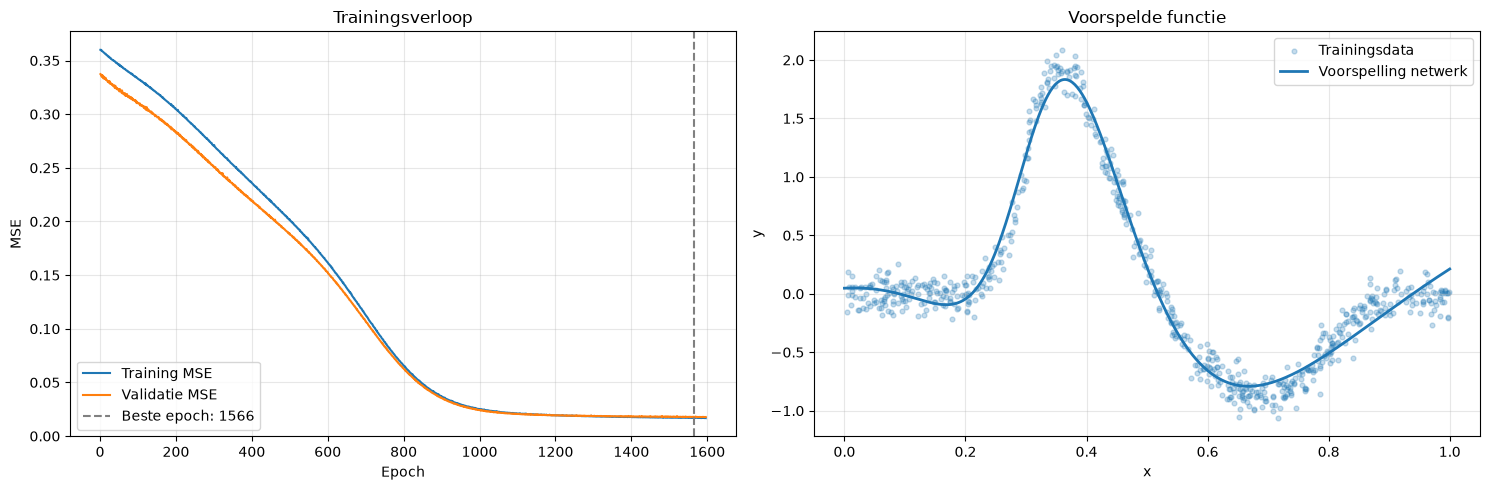

Aantal uitgevoerde epochs: 1596
Beste epoch: 1566
Laagste validatie-MSE: 0.017688


In [23]:

# Early stopping instellen
early_stopping_1 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

# Eerste neurale netwerk trainen
history_1 = model_1.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=10000,
    batch_size=32,
    callbacks=[early_stopping_1],
    verbose=0
)

# Trainingsresultaten ophalen
train_loss = history_1.history["loss"]
val_loss = history_1.history["val_loss"]

epochs = np.arange(1, len(train_loss) + 1)
best_epoch_1 = int(np.argmin(val_loss) + 1)

# Voorspelde functie berekenen
x_plot = np.linspace(0, 1, 500).reshape(-1, 1)
y_pred_1 = model_1.predict(x_plot, verbose=0)

# Twee grafieken naast elkaar
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Links: trainingsverloop
axes[0].plot(epochs, train_loss, label="Training MSE")
axes[0].plot(epochs, val_loss, label="Validatie MSE")

axes[0].axvline(
    best_epoch_1,
    color="gray",
    linestyle="--",
    label=f"Beste epoch: {best_epoch_1}"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].set_title("Trainingsverloop")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Rechts: voorspelde functie
axes[1].scatter(
    x_train, y_train,
    alpha=0.25,
    s=12,
    label="Trainingsdata"
)

axes[1].plot(
    x_plot, y_pred_1,
    linewidth=2,
    label="Voorspelling netwerk"
)

axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Voorspelde functie")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Resultaten weergeven
print(f"Aantal uitgevoerde epochs: {len(train_loss)}")
print(f"Beste epoch: {best_epoch_1}")
print(f"Laagste validatie-MSE: {min(val_loss):.6f}")


## Experiment 1 – Vier neuronen, 500 epochs
De validatie-MSE daalt naar 0,337590, een verbetering van 35,6% ten opzichte van het nulmodel. Toch onderschat het netwerk de piek rond (x=0,35) sterk en volgt het de daling en het rechterdeel van de functie onvoldoende.

Omdat de MSE bij epoch 500 nog daalt, wijst dit eerder op onvoldoende training dan op een gebrek aan modelcapaciteit. Daarom verhoog ik de trainingsduur naar 2.000 epochs zonder de architectuur te veranderen.

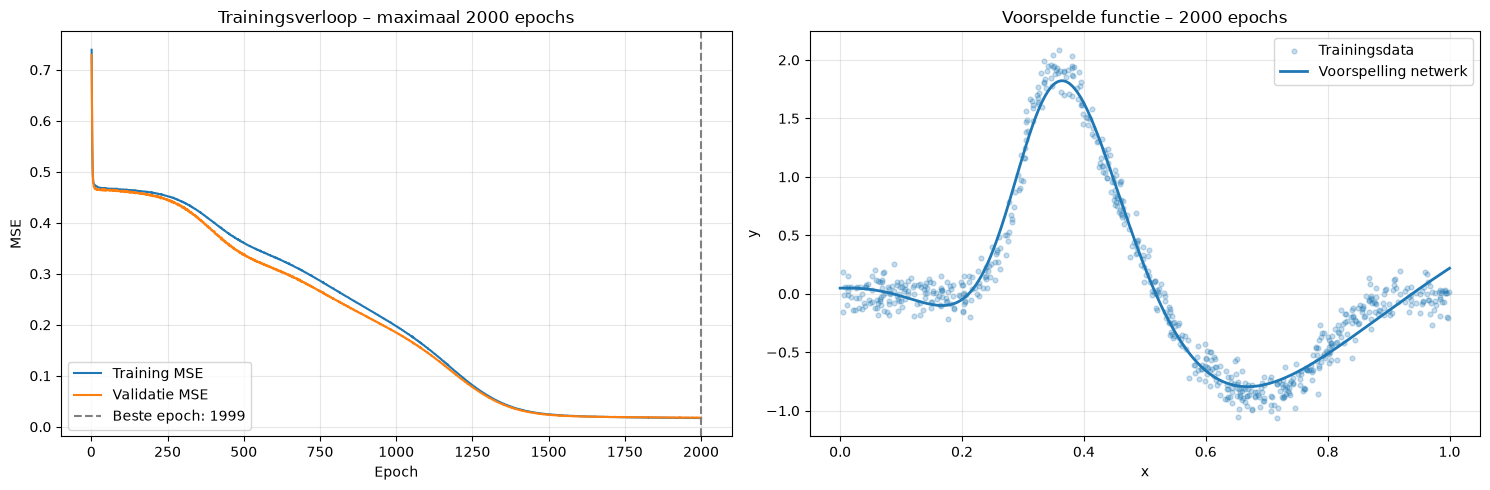

Aantal uitgevoerde epochs: 2000
Beste epoch: 1999
Validatie-MSE experiment 1: 0.337590
Validatie-MSE experiment 2: 0.017790
Verbetering: 94.73%


In [13]:

# Dezelfde initialisatie als experiment 1
keras.utils.set_random_seed(42)

# Hetzelfde netwerk opnieuw opbouwen
model_2 = keras.Sequential([
    keras.layers.Input(shape=(1,)),
    keras.layers.Dense(4, activation="tanh", name="hidden_layer"),
    keras.layers.Dense(1, activation="linear", name="output_layer")
])

# Dezelfde optimizer en loss-functie
model_2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

# Dezelfde early stopping-instellingen
early_stopping_2 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

# Trainen met maximaal 2000 epochs
history_2 = model_2.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=2000,
    batch_size=32,
    callbacks=[early_stopping_2],
    verbose=0
)

# Trainingsresultaten ophalen
train_loss_2 = history_2.history["loss"]
val_loss_2 = history_2.history["val_loss"]

epochs_2 = np.arange(1, len(train_loss_2) + 1)
best_epoch_2 = int(np.argmin(val_loss_2) + 1)

# Voorspelde functie berekenen
x_plot = np.linspace(0, 1, 500).reshape(-1, 1)
y_pred_2 = model_2.predict(x_plot, verbose=0)

# Twee grafieken naast elkaar
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Links: trainingsverloop
axes[0].plot(epochs_2, train_loss_2, label="Training MSE")
axes[0].plot(epochs_2, val_loss_2, label="Validatie MSE")

axes[0].axvline(
    best_epoch_2,
    color="gray",
    linestyle="--",
    label=f"Beste epoch: {best_epoch_2}"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].set_title("Trainingsverloop – maximaal 2000 epochs")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Rechts: voorspelde functie
axes[1].scatter(
    x_train, y_train,
    alpha=0.25,
    s=12,
    label="Trainingsdata"
)

axes[1].plot(
    x_plot, y_pred_2,
    linewidth=2,
    label="Voorspelling netwerk"
)

axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Voorspelde functie – 2000 epochs")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Vergelijking met experiment 1
mse_val_1 = min(history_1.history["val_loss"])
mse_val_2 = min(val_loss_2)

print(f"Aantal uitgevoerde epochs: {len(train_loss_2)}")
print(f"Beste epoch: {best_epoch_2}")
print(f"Validatie-MSE experiment 1: {mse_val_1:.6f}")
print(f"Validatie-MSE experiment 2: {mse_val_2:.6f}")
print(f"Verbetering: {(mse_val_1 - mse_val_2) / mse_val_1 * 100:.2f}%")
 

## Experiment 2 – Vier neuronen, 2.000 epochs

De validatie-MSE daalt naar 0,017790, een verbetering van **94,73%** ten opzichte van experiment 1. Het netwerk benadert nu zowel de piek als het minimum goed. Alleen richting (x=1) stijgt de voorspelling verder dan de meeste waarnemingen.

De training- en validatie-MSE liggen dicht bij elkaar, zonder duidelijke aanwijzingen voor overfitting. De verbetering bevestigt dat 500 epochs onvoldoende waren.

Nu de referentiearchitectuur goed presteert, onderzoek ik of drie neuronen een vergelijkbare nauwkeurigheid kunnen bereiken met minder parameters.


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer (Dense)            │ (None, 3)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10 (40.00 B)

 Trainable params: 10 (40.00 B)

 Non-trainable params: 0 (0.00 B)

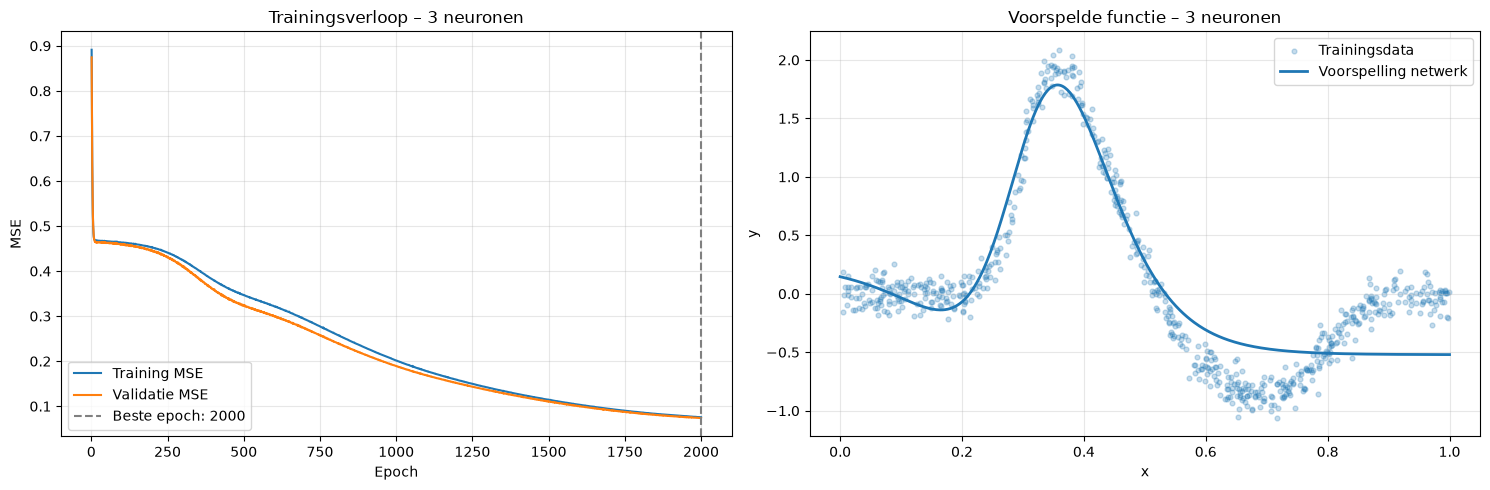

Aantal uitgevoerde epochs: 2000
Beste epoch: 2000
Validatie-MSE experiment 2: 0.017790
Validatie-MSE experiment 3: 0.073708
Verschil t.o.v. experiment 2: +314.33%


In [14]:

# Reproduceerbare initialisatie
keras.utils.set_random_seed(42)

# Netwerk met drie tanh-neuronen
model_3 = keras.Sequential([
    keras.layers.Input(shape=(1,)),
    keras.layers.Dense(3, activation="tanh", name="hidden_layer"),
    keras.layers.Dense(1, activation="linear", name="output_layer")
])

# Model configureren
model_3.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

# Controleer het aantal parameters
model_3.summary()

# Early stopping instellen
early_stopping_3 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

# Model trainen
history_3 = model_3.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=2000,
    batch_size=32,
    callbacks=[early_stopping_3],
    verbose=0
)

# Trainingsresultaten
train_loss_3 = history_3.history["loss"]
val_loss_3 = history_3.history["val_loss"]

epochs_3 = np.arange(1, len(train_loss_3) + 1)
best_epoch_3 = int(np.argmin(val_loss_3) + 1)

# Voorspelde functie
x_plot = np.linspace(0, 1, 500).reshape(-1, 1)
y_pred_3 = model_3.predict(x_plot, verbose=0)

# Twee grafieken naast elkaar
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Links: trainingsverloop
axes[0].plot(epochs_3, train_loss_3, label="Training MSE")
axes[0].plot(epochs_3, val_loss_3, label="Validatie MSE")

axes[0].axvline(
    best_epoch_3,
    color="gray",
    linestyle="--",
    label=f"Beste epoch: {best_epoch_3}"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].set_title("Trainingsverloop – 3 neuronen")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Rechts: voorspelde functie
axes[1].scatter(
    x_train, y_train,
    alpha=0.25,
    s=12,
    label="Trainingsdata"
)

axes[1].plot(
    x_plot, y_pred_3,
    linewidth=2,
    label="Voorspelling netwerk"
)

axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Voorspelde functie – 3 neuronen")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Resultaten vergelijken
mse_val_2 = min(history_2.history["val_loss"])
mse_val_3 = min(val_loss_3)

print(f"Aantal uitgevoerde epochs: {len(train_loss_3)}")
print(f"Beste epoch: {best_epoch_3}")
print(f"Validatie-MSE experiment 2: {mse_val_2:.6f}")
print(f"Validatie-MSE experiment 3: {mse_val_3:.6f}")
print(f"Verschil t.o.v. experiment 2: {(mse_val_3 - mse_val_2) / mse_val_2 * 100:+.2f}%")


## Experiment 3 – Drie neuronen, 2.000 epochs

Met drie neuronen daalt het aantal parameters van 13 naar 10. De validatie-MSE stijgt echter naar 0,073708, ruim vier keer zo hoog als bij vier neuronen.

De piek wordt redelijk benaderd, maar het minimum is te ondiep en de voorspelling blijft rechts vrijwel constant rond −0,5. Omdat de MSE bij epoch 2000 nog daalt, kan ik onvoldoende modelcapaciteit nog niet onderscheiden van onvoldoende training.

Daarom voer ik in het volgende experiment een epoch van 5000 uit.

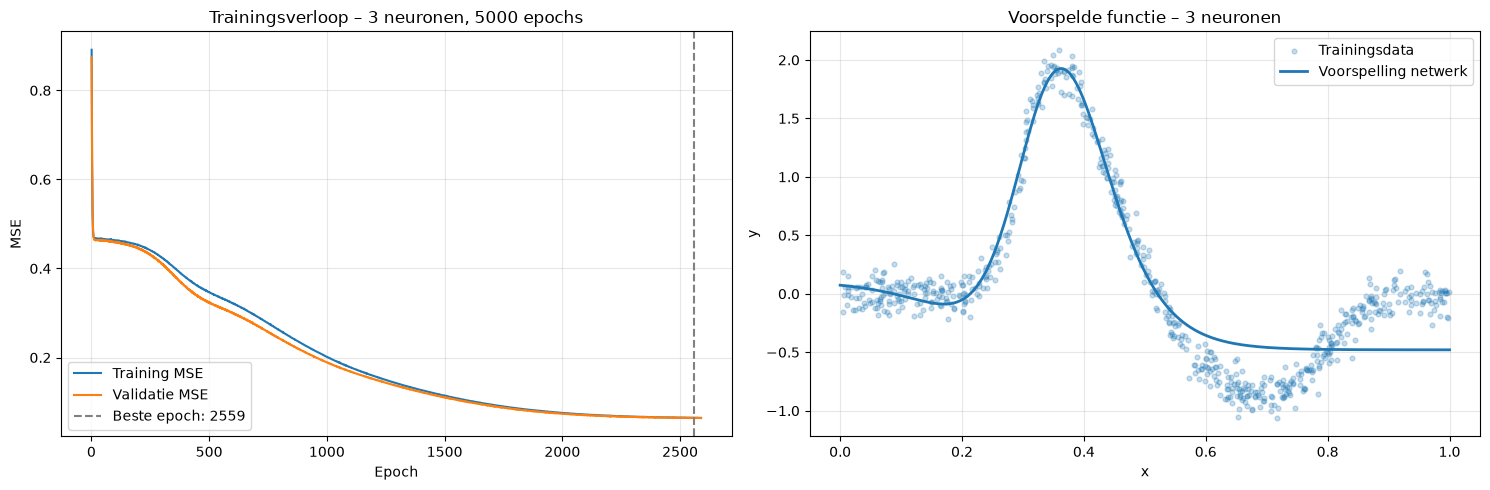

Aantal uitgevoerde epochs: 2589
Beste epoch: 2559
Validatie-MSE experiment 3: 0.073708
Validatie-MSE experiment 4: 0.064021
Verschil t.o.v. experiment 3: -13.14%
Verschil t.o.v. 4 neuronen: +259.88%


In [15]:

# Reproduceerbare initialisatie
keras.utils.set_random_seed(42)

# Netwerk met drie tanh-neuronen opnieuw opbouwen
model_4 = keras.Sequential([
    keras.layers.Input(shape=(1,)),
    keras.layers.Dense(3, activation="tanh", name="hidden_layer"),
    keras.layers.Dense(1, activation="linear", name="output_layer")
])

# Dezelfde optimizer en loss-functie
model_4.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

# Early stopping
early_stopping_4 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

# Trainen met maximaal 5000 epochs
history_4 = model_4.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=5000,
    batch_size=32,
    callbacks=[early_stopping_4],
    verbose=0
)

# Trainingsresultaten
train_loss_4 = history_4.history["loss"]
val_loss_4 = history_4.history["val_loss"]

epochs_4 = np.arange(1, len(train_loss_4) + 1)
best_epoch_4 = int(np.argmin(val_loss_4) + 1)

# Voorspelde functie berekenen
x_plot = np.linspace(0, 1, 500).reshape(-1, 1)
y_pred_4 = model_4.predict(x_plot, verbose=0)

# Twee grafieken naast elkaar
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Links: trainingsverloop
axes[0].plot(epochs_4, train_loss_4, label="Training MSE")
axes[0].plot(epochs_4, val_loss_4, label="Validatie MSE")

axes[0].axvline(
    best_epoch_4,
    color="gray",
    linestyle="--",
    label=f"Beste epoch: {best_epoch_4}"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].set_title("Trainingsverloop – 3 neuronen, 5000 epochs")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Rechts: voorspelde functie
axes[1].scatter(
    x_train, y_train,
    alpha=0.25,
    s=12,
    label="Trainingsdata"
)

axes[1].plot(
    x_plot, y_pred_4,
    linewidth=2,
    label="Voorspelling netwerk"
)

axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Voorspelde functie – 3 neuronen")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Resultaten vergelijken
mse_val_3 = min(history_3.history["val_loss"])
mse_val_4 = min(val_loss_4)

print(f"Aantal uitgevoerde epochs: {len(train_loss_4)}")
print(f"Beste epoch: {best_epoch_4}")
print(f"Validatie-MSE experiment 3: {mse_val_3:.6f}")
print(f"Validatie-MSE experiment 4: {mse_val_4:.6f}")
print(f"Verschil t.o.v. experiment 3: {(mse_val_4 - mse_val_3) / mse_val_3 * 100:+.2f}%")
print(f"Verschil t.o.v. 4 neuronen: {(mse_val_4 - mse_val_2) / mse_val_2 * 100:+.2f}%")


## Experiment 4 – Drie neuronen, langere training

Om te onderzoeken of drie neuronen onvoldoende capaciteit hebben of simpelweg meer training nodig hebben, verhoog ik het maximum van 2.000 naar 5.000 epochs. De overige instellingen blijven gelijk.


`EarlyStopping` beëindigt de training na 2.589 epochs, met de laagste validatie-MSE van **0,064021** bij epoch 2559. Dit is een verbetering van 13,14% ten opzichte van experiment 3, maar nog steeds 259,88% hoger dan bij vier neuronen (0,017790).

De training- en validatie-MSE vlakken af zonder duidelijke aanwijzingen voor overfitting. Ook blijft de voorspelling vanaf ongeveer \(x=0,8\) vrijwel constant rond −0,5, terwijl de werkelijke functie weer richting nul stijgt.

Langer trainen lost dit probleem dus niet op. Dit wijst mogelijk op onvoldoende modelcapaciteit, hoewel de initialisatie ook invloed kan hebben. Het verschil is bovendien veel groter dan mijn acceptatiemarge van 5%.

Daarom behoud ik vier neuronen voorlopig als betere keuze en onderzoek ik in experiment 5 of een vijfde neuron nog verbetering oplevert. Hiervoor verhoog ik het aantal parameters van 13 naar 16 en houd ik de overige trainingsinstellingen gelijk.

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer (Dense)            │ (None, 5)              │            10 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16 (64.00 B)

 Trainable params: 16 (64.00 B)

 Non-trainable params: 0 (0.00 B)

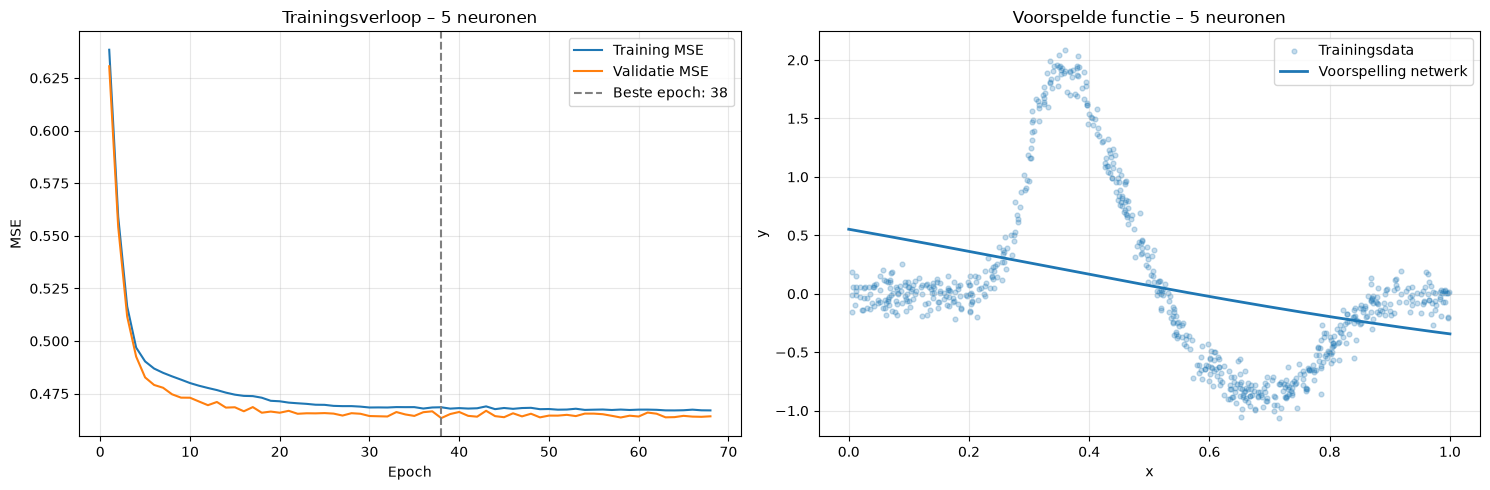

Aantal uitgevoerde epochs: 68
Beste epoch: 38
Validatie-MSE 4 neuronen: 0.017790
Validatie-MSE 5 neuronen: 0.463374
Afwijking 4 neuronen t.o.v. beste: 0.00%
Voorlopige voorkeur: 4 neuronen (binnen 5%-marge)


In [16]:

# Reproduceerbare initialisatie
keras.utils.set_random_seed(42)

# Netwerk met vijf tanh-neuronen
model_5 = keras.Sequential([
    keras.layers.Input(shape=(1,)),
    keras.layers.Dense(5, activation="tanh", name="hidden_layer"),
    keras.layers.Dense(1, activation="linear", name="output_layer")
])

model_5.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

model_5.summary()

# Early stopping
early_stopping_5 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

# Model trainen
history_5 = model_5.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=2000,
    batch_size=32,
    callbacks=[early_stopping_5],
    verbose=0
)

# Resultaten
train_loss_5 = history_5.history["loss"]
val_loss_5 = history_5.history["val_loss"]

epochs_5 = np.arange(1, len(train_loss_5) + 1)
best_epoch_5 = int(np.argmin(val_loss_5) + 1)

# Voorspelde functie
x_plot = np.linspace(0, 1, 500).reshape(-1, 1)
y_pred_5 = model_5.predict(x_plot, verbose=0)

# Grafieken
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(epochs_5, train_loss_5, label="Training MSE")
axes[0].plot(epochs_5, val_loss_5, label="Validatie MSE")
axes[0].axvline(
    best_epoch_5,
    color="gray",
    linestyle="--",
    label=f"Beste epoch: {best_epoch_5}"
)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].set_title("Trainingsverloop – 5 neuronen")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].scatter(
    x_train, y_train,
    alpha=0.25,
    s=12,
    label="Trainingsdata"
)
axes[1].plot(
    x_plot, y_pred_5,
    linewidth=2,
    label="Voorspelling netwerk"
)
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Voorspelde functie – 5 neuronen")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Vergelijking met vier neuronen
mse_val_5 = min(val_loss_5)
mse_best = min(mse_val_2, mse_val_5)
verschil_4 = (mse_val_2 - mse_best) / mse_best * 100

print(f"Aantal uitgevoerde epochs: {len(train_loss_5)}")
print(f"Beste epoch: {best_epoch_5}")
print(f"Validatie-MSE 4 neuronen: {mse_val_2:.6f}")
print(f"Validatie-MSE 5 neuronen: {mse_val_5:.6f}")
print(f"Afwijking 4 neuronen t.o.v. beste: {verschil_4:.2f}%")

if verschil_4 <= 5:
    print("Voorlopige voorkeur: 4 neuronen (binnen 5%-marge)")
else:
    print("Voorlopige voorkeur: 5 neuronen (meer dan 5% verbetering)")



## Experiment 5 – Vijf neuronen met early stopping
 
Het netwerk stopt al na 68 epochs, met de beste validatie-MSE van 0,463374 bij epoch 38. De voorspelling is vrijwel lineair en mist zowel de piek als het minimum.

De MSE blijft aanvankelijk rond 0,46 hangen. In eerdere experimenten zag ik dat zo'n plateau later alsnog kan worden doorbroken. Daarom vermoed ik dat early stopping met patience 30 hier te vroeg ingrijpt.

Om dit te controleren herhaal ik de training zonder early stopping.


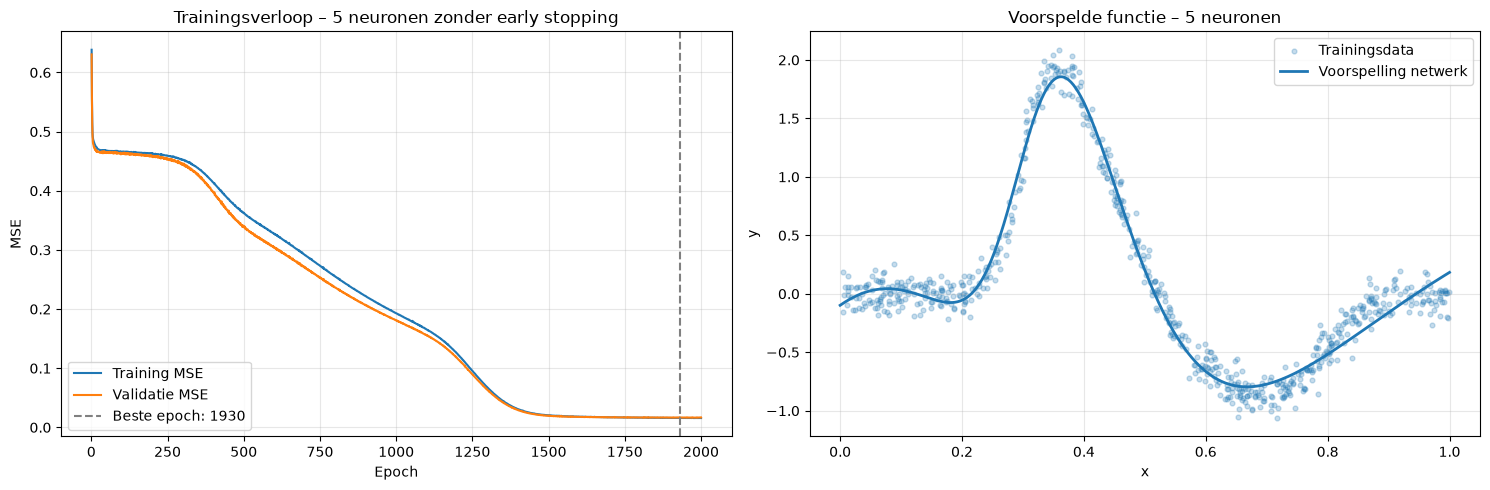

Aantal uitgevoerde epochs: 2000
Beste epoch: 1930
Validatie-MSE experiment 5: 0.463374
Laagste validatie-MSE experiment 6: 0.016470
Validatie-MSE 4 neuronen: 0.017790


In [17]:

# Reproduceerbare initialisatie
keras.utils.set_random_seed(42)

# Netwerk met vijf tanh-neuronen opnieuw opbouwen
model_6 = keras.Sequential([
    keras.layers.Input(shape=(1,)),
    keras.layers.Dense(5, activation="tanh", name="hidden_layer"),
    keras.layers.Dense(1, activation="linear", name="output_layer")
])

model_6.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

# Trainen zonder early stopping
history_6 = model_6.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=2000,
    batch_size=32,
    verbose=0
)

# Trainingsresultaten
train_loss_6 = history_6.history["loss"]
val_loss_6 = history_6.history["val_loss"]

epochs_6 = np.arange(1, len(train_loss_6) + 1)
best_epoch_6 = int(np.argmin(val_loss_6) + 1)

# Voorspelde functie
x_plot = np.linspace(0, 1, 500).reshape(-1, 1)
y_pred_6 = model_6.predict(x_plot, verbose=0)

# Grafieken
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(epochs_6, train_loss_6, label="Training MSE")
axes[0].plot(epochs_6, val_loss_6, label="Validatie MSE")
axes[0].axvline(
    best_epoch_6,
    color="gray",
    linestyle="--",
    label=f"Beste epoch: {best_epoch_6}"
)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].set_title("Trainingsverloop – 5 neuronen zonder early stopping")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].scatter(
    x_train, y_train,
    alpha=0.25,
    s=12,
    label="Trainingsdata"
)
axes[1].plot(
    x_plot, y_pred_6,
    linewidth=2,
    label="Voorspelling netwerk"
)
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Voorspelde functie – 5 neuronen")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Resultaten
mse_val_6 = min(val_loss_6)

print(f"Aantal uitgevoerde epochs: {len(train_loss_6)}")
print(f"Beste epoch: {best_epoch_6}")
print(f"Validatie-MSE experiment 5: {mse_val_5:.6f}")
print(f"Laagste validatie-MSE experiment 6: {mse_val_6:.6f}")
print(f"Validatie-MSE 4 neuronen: {mse_val_2:.6f}")


## Experiment 6 – Vijf neuronen zonder early stopping

Zonder early stopping daalt de validatie-MSE na een langdurig plateau alsnog sterk. De laagste waarde is 0,016470 bij epoch 1930.

Dit is 7,42% lager dan bij vier neuronen (0,017790). De extra modelcapaciteit levert dus een kleine verbetering op, hoewel de voorspelling aan de rechterkant nog steeds afwijkt.

Experiment 5 en 6 laten vooral zien dat early stopping met patience 30 voor dit probleem onbetrouwbaar kan zijn. Het trainingsverloop kent plateaus die niet betekenen dat verdere verbetering uitblijft.

Omdat het verschil tussen vier en vijf neuronen klein is, onderzoek ik of deze uitkomst afhankelijk is van de initialisatie seed. ik ga een wat langere experiment runnen waarvan ik 5 seeds bekijk.


In [18]:

import pandas as pd

# Instellingen
seeds = [42, 123, 456, 789, 2026]
architecturen = [4, 5]

resultaten_7 = []

for neuronen in architecturen:
    for seed in seeds:
        keras.utils.set_random_seed(seed)

        # Nieuw model opbouwen
        model = keras.Sequential([
            keras.layers.Input(shape=(1,)),
            keras.layers.Dense(neuronen, activation="tanh"),
            keras.layers.Dense(1, activation="linear")
        ])

        model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=0.001),
            loss="mse"
        )

        # Trainen zonder early stopping
        history = model.fit(
            x_train, y_train,
            validation_data=(x_val, y_val),
            epochs=2000,
            batch_size=32,
            verbose=0
        )

        # Beste validatie-MSE tijdens de training
        val_losses = history.history["val_loss"]
        beste_epoch = int(np.argmin(val_losses) + 1)
        beste_mse = float(np.min(val_losses))

        resultaten_7.append({
            "Neuronen": neuronen,
            "Seed": seed,
            "Beste epoch": beste_epoch,
            "Validatie-MSE": beste_mse
        })

        print(
            f"{neuronen} neuronen | Seed {seed} | "
            f"Beste epoch: {beste_epoch} | "
            f"Validatie-MSE: {beste_mse:.6f}"
        )

# Resultaten verzamelen
df_resultaten_7 = pd.DataFrame(resultaten_7)

# Samenvatting per architectuur
samenvatting_7 = (
    df_resultaten_7
    .groupby("Neuronen")["Validatie-MSE"]
    .agg(["mean", "std", "min", "max"])
)

print("\nResultaten per training:")
display(df_resultaten_7)

print("\nSamenvatting per architectuur:")
display(samenvatting_7)


4 neuronen | Seed 42 | Beste epoch: 1999 | Validatie-MSE: 0.017790
4 neuronen | Seed 123 | Beste epoch: 1991 | Validatie-MSE: 0.017398
4 neuronen | Seed 456 | Beste epoch: 1977 | Validatie-MSE: 0.016945
4 neuronen | Seed 789 | Beste epoch: 2000 | Validatie-MSE: 0.056189
4 neuronen | Seed 2026 | Beste epoch: 2000 | Validatie-MSE: 0.080086
5 neuronen | Seed 42 | Beste epoch: 1930 | Validatie-MSE: 0.016470
5 neuronen | Seed 123 | Beste epoch: 1991 | Validatie-MSE: 0.017386
5 neuronen | Seed 456 | Beste epoch: 1995 | Validatie-MSE: 0.017261
5 neuronen | Seed 789 | Beste epoch: 1997 | Validatie-MSE: 0.035579
5 neuronen | Seed 2026 | Beste epoch: 2000 | Validatie-MSE: 0.090853

Resultaten per training:


,Neuronen,Seed,Beste epoch,Validatie-MSE
0,4,42,1999,0.017790
1,4,123,1991,0.017398
2,4,456,1977,0.016945
3,4,789,2000,0.056189
4,4,2026,2000,0.080086
5,5,42,1930,0.016470
6,5,123,1991,0.017386
7,5,456,1995,0.017261
8,5,789,1997,0.035579
9,5,2026,2000,0.090853



Samenvatting per architectuur:


,mean,std,min,max
Neuronen,,,,
4,0.037682,0.029059,0.016945,0.080086
5,0.035510,0.031964,0.016470,0.090853


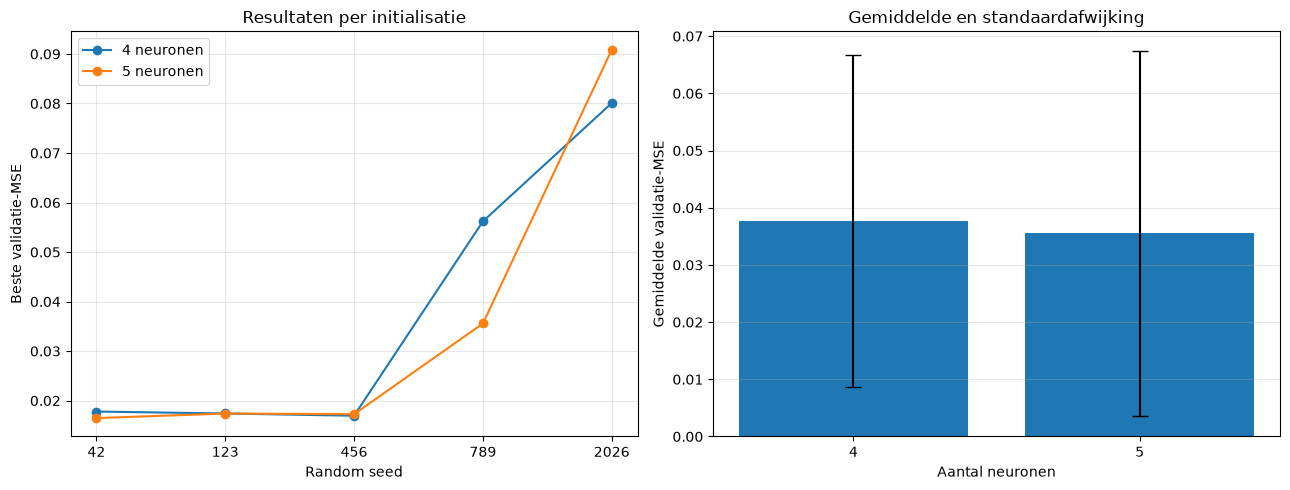

Gemiddelde MSE – 4 neuronen: 0.037682
Gemiddelde MSE – 5 neuronen: 0.035510
Afwijking 4 neuronen t.o.v. beste: 6.12%
Voorlopige voorkeur: 5 neuronen


In [19]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Links: resultaten per seed
for neuronen in architecturen:
    subset = df_resultaten_7[
        df_resultaten_7["Neuronen"] == neuronen
    ]

    axes[0].plot(
        subset["Seed"].astype(str),
        subset["Validatie-MSE"],
        marker="o",
        label=f"{neuronen} neuronen"
    )

axes[0].set_xlabel("Random seed")
axes[0].set_ylabel("Beste validatie-MSE")
axes[0].set_title("Resultaten per initialisatie")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Rechts: gemiddelde met standaardafwijking
axes[1].bar(
    samenvatting_7.index.astype(str),
    samenvatting_7["mean"],
    yerr=samenvatting_7["std"],
    capsize=6
)

axes[1].set_xlabel("Aantal neuronen")
axes[1].set_ylabel("Gemiddelde validatie-MSE")
axes[1].set_title("Gemiddelde en standaardafwijking")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# 5%-regel toepassen op de gemiddelden
gemiddelde_4 = samenvatting_7.loc[4, "mean"]
gemiddelde_5 = samenvatting_7.loc[5, "mean"]

beste_gemiddelde = min(gemiddelde_4, gemiddelde_5)
afwijking_4 = (gemiddelde_4 - beste_gemiddelde) / beste_gemiddelde * 100

print(f"Gemiddelde MSE – 4 neuronen: {gemiddelde_4:.6f}")
print(f"Gemiddelde MSE – 5 neuronen: {gemiddelde_5:.6f}")
print(f"Afwijking 4 neuronen t.o.v. beste: {afwijking_4:.2f}%")

if afwijking_4 <= 5:
    print("Voorlopige voorkeur: 4 neuronen")
else:
    print("Voorlopige voorkeur: 5 neuronen")


## Experiment 7 – Invloed van random initialisatie

In experiment 2 en 6 behaalde het netwerk met vijf neuronen een 7,42% lagere validatie-MSE dan het netwerk met vier neuronen (0,016470 tegenover 0,017790). Omdat dit slechts één initialisatie betrof, wil ik onderzoeken of vijf neuronen ook bij andere initialisaties beter presteren.

Ik train beide architecturen daarom vijf keer met dezelfde random seeds, Adam (learning rate 0,001), batch size 32 en maximaal 2.000 epochs. Early stopping laat ik weg, omdat experiment 5 liet zien dat dit de training voortijdig kan beëindigen.

*Figuur 9. Validatie-MSE per initialisatie en gemiddelde met standaardafwijking.*

Het netwerk met vier neuronen behaalt een gemiddelde validatie-MSE van **0,037682**, tegenover **0,035510** bij vijf neuronen. Vijf neuronen presteren daarmee gemiddeld 5,8% beter. Het verschil is echter klein vergeleken met de standaardafwijkingen van respectievelijk 0,029059 en 0,031964.

Bij beide architecturen behalen drie van de vijf initialisaties een MSE onder 0,02. De overige runs presteren aanzienlijk slechter. Daarnaast bereiken meerdere modellen hun beste resultaat pas rond epoch 2.000, waardoor ik niet kan uitsluiten dat een langere training de resultaten zou veranderen.

Volgens mijn vooraf gekozen 5%-regel ligt de gemiddelde MSE van vier neuronen **6,12% boven die van vijf neuronen**. Daarom kies ik voorlopig voor vijf neuronen (16 parameters), hoewel de grote spreiding onvoldoende bewijs geeft dat deze architectuur structureel beter is.

Ik voer geen aanvullende langdurige training uit vanwege de rekentijd. De invloed van initialisatie en mogelijke onvolledige convergentie neem ik daarom mee als beperking van mijn modelkeuze.

## Conclusie en modelkeuze

De experimenten laten zien dat zowel de trainingsduur als de random initialisatie veel invloed hebben op de prestaties. Drie neuronen blijken onvoldoende om de oorspronkelijke functie nauwkeurig te benaderen. Vier en vijf neuronen kunnen beide een validatie-MSE rond 0,017 behalen.

Ik selecteer eerst de **architectuur** op basis van de gemiddelde validatie-MSE over vijf initialisaties. Vijf neuronen behalen gemiddeld 0,035510, tegenover 0,037682 bij vier neuronen. Het eenvoudigere model ligt daarmee 6,12% boven het beste gemiddelde en valt net buiten mijn vooraf vastgestelde 5%-marge. Daarom kies ik voor vijf tanh-neuronen.

Deze keuze is niet overtuigend beter op basis van de resultaten alleen, omdat de spreiding tussen initialisaties groot is.

Vervolgens selecteer ik de **afzonderlijke getrainde uitvoering**. De beste run met vijf neuronen is die met seed 42 uit experiment 6 (`model_6`). Deze behaalde tijdens de training de laagste validatie-MSE van 0,016470, bij epoch 1930.

Een belangrijk aandachtspunt is dat ik de gewichten van epoch 1930 niet afzonderlijk heb opgeslagen. Omdat ik zonder early stopping heb getraind, bevat `model_6` de gewichten van **epoch 2000**. De uiteindelijke validatie-MSE van dit model is 0,016684, iets hoger dan de beste tussentijdse score.

Ik gebruik daarom `model_6` met de gewichten van epoch 2000 voor deel 4, 5 en 6. Hiermee blijft de evaluatie consistent en wordt de testset niet gebruikt om achteraf een ander model te selecteren.

Mijn definitieve keuze is dus een netwerk met vijf tanh-neuronen en 16 trainbare parameters, getraind met seed 42 gedurende 2000 epochs. De gevoeligheid voor initialisatie en de mogelijke onvolledige convergentie blijven beperkingen van deze keuze.


# Deel 4

In deel 3 heb ik gekozen voor vijf tanh-neuronen. Nu vergelijk ik de voorspelde functie \(\hat f(x)\) met de oorspronkelijke, ruisvrije functie \(f(x)\). Zo kan ik beoordelen of het netwerk het onderliggende verband heeft geleerd en waar nog afwijkingen zitten.

We gebruiken hiervoor het al getrainde model_6 uit experiment 6 (vijf neuronen, seed 42). Er hoeft dus niet opnieuw getraind te worden. De testset blijft buiten beschouwing.

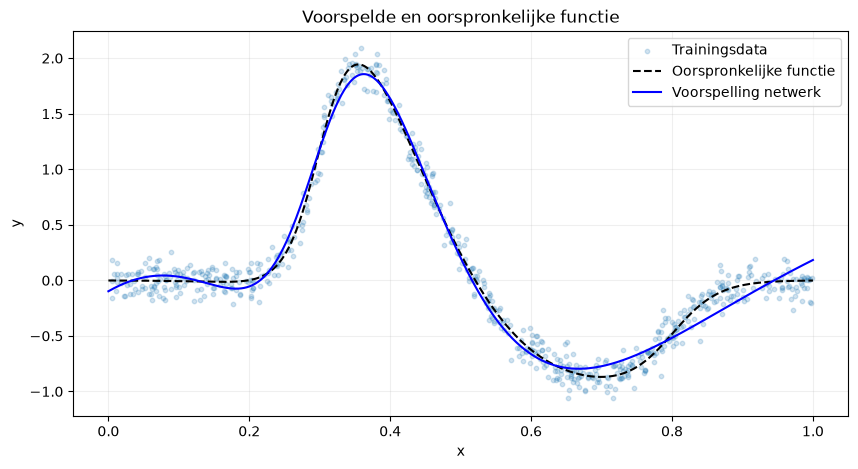

In [22]:

x_plot = np.linspace(0, 1, 500).reshape(-1, 1)

y_echt = f(x_plot)
y_voorspeld = model_6.predict(x_plot, verbose=0)

plt.figure(figsize=(10, 5))
plt.scatter(x_train, y_train, s=10, alpha=0.2, label="Trainingsdata")
plt.plot(x_plot, y_echt, "k--", label="Oorspronkelijke functie")
plt.plot(x_plot, y_voorspeld, "b-", label="Voorspelling netwerk")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Voorspelde en oorspronkelijke functie")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


Het netwerk met vijf tanh-neuronen benadert de oorspronkelijke functie behoorlijk goed. De piek rond (x=0,35) en het minimum rond (x=0,65) worden goed gevolgd, al wordt de piek iets onderschat.

De grootste afwijking zie ik aan de rechterkant. Vanaf ongeveer (x=0,8) blijft de voorspelling stijgen, terwijl de oorspronkelijke functie richting nul afvlakt. Het netwerk heeft dus het algemene patroon geleerd, maar niet alle lokale eigenschappen correct gereconstrueerd.

Ik concludeer dat het netwerk de oorspronkelijke functie goed benadert, maar niet exact heeft achterhaald. Ondanks dat vijf tanh-neuronen voldoende capaciteit hebben, garandeert dit niet dat de training de oorspronkelijke parameters terugvindt. Ik ben echter best tevreden ver het resultaat.

# Deel 5

Bestudeer de gewichten van je model, zou je zeggen dat je de oorspronkelijke $f$ achterhaald hebt?


## Wiskundige analyse van het netwerk

In deel 4 zag ik dat het netwerk de oorspronkelijke functie goed benadert. Ik wil nu onderzoeken hoe het netwerk deze voorspelling opbouwt en of de geleerde tanh-termen overeenkomen met de oorspronkelijke functie.

De netwerkfunctie heeft de vorm:

$$
\hat f(x)=c+\sum_{i=1}^{5}a_i\tanh(w_ix+b_i)
$$

Hierbij zijn $w_i$ en $b_i$ de parameters van de verborgen neuronen, $a_i$ de outputgewichten en $c$ de outputbias.

In [29]:

w, b = model_6.layers[0].get_weights()
a, c = model_6.layers[1].get_weights()

w = w.flatten()
a = a.flatten()

for i in range(len(w)):
    print(f"Term {i+1}: {a[i]:+.3f} · tanh({w[i]:+.3f}x {b[i]:+.3f})")

print(f"Outputbias: {c[0]:+.3f}")


Term 1: -2.544 · tanh(+4.329x -1.438)
Term 2: -3.495 · tanh(+5.309x -2.088)
Term 3: +1.049 · tanh(+5.651x +0.499)
Term 4: -3.164 · tanh(-1.865x +1.095)
Term 5: -3.411 · tanh(-11.552x +3.446)
Outputbias: -0.312



### Mijn geleerde functie

Het getrainde neurale netwerk heeft de volgende functie geleerd:

$$
\begin{aligned}
\hat{f}(x) ={}&
-2.544\tanh(4.329x-1.438)\\
&-3.495\tanh(5.309x-2.088)\\
&+1.049\tanh(5.651x+0.499)\\
&-3.164\tanh(-1.865x+1.095)\\
&-3.411\tanh(-11.552x+3.446)\\
&-0.312
\end{aligned}
$$

Deze functie bestaat uit vijf geleerde tanh-termen en een outputbias van −0,312. De parameters zijn afgerond op drie decimalen.

Hoewel de oorspronkelijke functie uit vier tanh-termen bestaat, heeft mijn netwerk een andere combinatie geleerd waarmee het de oorspronkelijke functievorm goed benadert.

### Vergelijking met de oorspronkelijke functie

De oorspronkelijke functie is:

$$
f(x)=1.5\tanh(20x-6)-\tanh(10x-4)-\tanh(8x-4)+0.5\tanh(15x-12)
$$

De oorspronkelijke functie heeft vier tanh-termen met inputgewichten van 8 tot 20. Mijn netwerk heeft vijf neuronen met absolute inputgewichten tussen 1,865 en 11,552. Ook de outputgewichten en biases wijken af.

Wat mij opvalt, is dat het netwerk met minder steile tanh-termen toch vrijwel dezelfde functievorm kan produceren. De neuronen compenseren elkaars bijdragen, waardoor de totale voorspelling veel nauwkeuriger is dan de afzonderlijke termen doen vermoeden.

### Conclusie deel 5

**Ik heb de oorspronkelijke functie goed benaderd, maar niet de oorspronkelijke parameters teruggevonden.** Het netwerk heeft een andere combinatie van tanh-termen geleerd die binnen het onderzochte interval vergelijkbare voorspellingen oplevert.

Dat is een belangrijk verschil: een lage MSE betekent niet automatisch dat het netwerk ook de oorspronkelijke wiskundige opbouw heeft achterhaald.

Hoewel ik voor vijf neuronen heb gekozen vanwege de iets lagere gemiddelde validatie-MSE, sluit een netwerk met vier neuronen beter aan bij de oorspronkelijke functie. Ook daarmee zou het terugvinden van de exacte parameters echter niet gegarandeerd zijn.


# Deel 6 

Ik evalueer het gekozen netwerk met vijf tanh-neuronen op de testset van 150 observaties. Deze data is nog niet gebruikt voor training of modelselectie.

Ik gebruik MSE als belangrijkste kwaliteitsmaat, omdat ik hiermee ook de eerdere experimenten heb beoordeeld. Daarnaast bereken ik de RMSE om de voorspelfout te vergelijken met de standaardafwijking van de toegevoegde ruis (0,1).


In [31]:

from sklearn.metrics import mean_squared_error, root_mean_squared_error

# Definitieve evaluatie van het gekozen netwerk
y_pred_test = model_6.predict(x_test, verbose=0)
y_pred_val = model_6.predict(x_val, verbose=0)

test_mse = mean_squared_error(y_test, y_pred_test)
test_rmse = root_mean_squared_error(y_test, y_pred_test)
val_mse = mean_squared_error(y_val, y_pred_val)

# Nulmodel is al getraind in deel 3
y_pred_nul_test = nulmodel.predict(x_test)
nulmodel_test_mse = mean_squared_error(y_test, y_pred_nul_test)

# Relatieve verbetering ten opzichte van het nulmodel
verbetering_test = (
    (nulmodel_test_mse - test_mse) / nulmodel_test_mse
) * 100

print(f"Validatie-MSE netwerk: {val_mse:.6f}")
print(f"Test-MSE netwerk:      {test_mse:.6f}")
print(f"Test-RMSE netwerk:     {test_rmse:.6f}")
print(f"Test-MSE nulmodel:     {nulmodel_test_mse:.6f}")
print(f"Verbetering testset:   {verbetering_test:.2f}%")
print(f"Ruisvariantie:         {0.01:.6f}")



Validatie-MSE netwerk: 0.016684
Test-MSE netwerk:      0.014565
Test-RMSE netwerk:     0.120685
Test-MSE nulmodel:     0.421050
Verbetering testset:   96.54%
Ruisvariantie:         0.010000



## Evaluatie testresultaten

Het gekozen netwerk met vijf tanh-neuronen behaalt een **test-MSE van 0,014565**, tegenover een validatie-MSE van 0,016684. De testfout is daarmee ongeveer 12,7% lager dan de validatiefout. Dit laat zien dat het model ook op ongeziene data goed presteert. Ik zie geen duidelijke aanwijzing voor overfitting, al kan het verschil tussen beide scores deels ontstaan door de beperkte omvang van de datasets en toevallige verschillen in de ruis.

De test-RMSE bedraagt **0,120685**. Dit ligt iets boven de standaardafwijking van de toegevoegde ruis (0,1). De test-MSE is daarnaast ongeveer 45,7% hoger dan de theoretische ruisvariantie van 0,01. Dit suggereert dat er naast de ruis nog enige afwijking in de voorspellingen zit. De ruisvariantie is hierbij een theoretisch referentiepunt en geen harde ondergrens voor deze specifieke testset.

In deel 4 zag ik al dat het netwerk vooral aan de rechterkant afwijkt van de oorspronkelijke functie. Dit kan bijdragen aan de hogere MSE, hoewel ik op basis van deze resultaten niet precies kan bepalen hoeveel.

### Vergelijking met het nulmodel

Om de prestaties beter te beoordelen, vergelijk ik mijn neurale netwerk met het nulmodel op dezelfde testset. Het nulmodel voorspelt voor iedere observatie het gemiddelde van de trainingslabels en leert dus geen verband tussen $x$ en $y$.

| Model | Validatie-MSE | Test-MSE |
|---|---:|---:|
| Nulmodel (DummyRegressor) | 0,524082 | 0,421050 |
| Neuraal netwerk (5 neuronen) | 0,016684 | 0,014565 |

Op de validatieset behaalt mijn netwerk een **96,8% lagere MSE** dan het nulmodel. Op de testset is de verbetering **96,54%**.

Deze vergelijking laat zien dat mijn netwerk aanzienlijk beter voorspelt dan een model dat alleen het gemiddelde gebruikt. Het netwerk heeft dus daadwerkelijk informatie uit het verband tussen $x$ en $y$ geleerd.

**Ik concludeer dat het netwerk goed generaliseert en de oorspronkelijke functie nauwkeurig benadert, maar nog niet optimaal voorspelt.** De testresultaten ondersteunen dat mijn model aanzienlijk beter presteert dan het nulmodel. Uit deel 5 blijkt echter dat een goede voorspelling niet betekent dat de oorspronkelijke functieparameters zijn teruggevonden.

## Reflectie op de requirements

Om te beoordelen of mijn model aan de oorspronkelijke doelstelling voldoet, vergelijk ik de resultaten met de requirements uit deel 1.

| Requirement | Beoordeling | Onderbouwing |
|---|---|---|
| **F1 – Continue voorspelling** | Voldaan | Het netwerk voorspelt één continue waarde voor iedere $x$ binnen $[0,1]$. |
| **F2 – Niet-lineair verband benaderen** | Voldaan | Het netwerk benadert de oorspronkelijke functievorm goed, al blijft vooral rechts een afwijking zichtbaar. |
| **F3 – Visuele vergelijking** | Voldaan | In deel 4 heb ik de voorspelde functie en de oorspronkelijke functie in dezelfde grafiek weergegeven. |
| **F4 – Parameters inzichtelijk** | Voldaan | In deel 5 heb ik de gewichten en biases uitgelezen en vergeleken met de oorspronkelijke functieparameters. |
| **T1 – Netwerkarchitectuur** | Voldaan | Het netwerk heeft één input, één verborgen laag met vijf tanh-neuronen en een lineaire output. |
| **T2 – Exacte representatie** | Voldaan voor de referentiearchitectuur | Een netwerk met vier tanh-neuronen kan de oorspronkelijke functie theoretisch exact representeren. Dit betekent niet dat de training deze parameters ook heeft teruggevonden. |
| **T3 – Maximaal 13 parameters** | Niet voldaan voor het eindmodel | Het referentienetwerk met vier neuronen heeft 13 trainbare parameters. Mijn gekozen netwerk met vijf neuronen heeft er 16. Deze afwijking heb ik bewust geaccepteerd vanwege de iets betere gemiddelde validatieprestaties. |
| **T4 – Geschikte loss-functie** | Voldaan | Ik heb MSE gebruikt, wat past bij regressie met normaal verdeelde ruis. |
| **T5 – Gescheiden datasets** | Voldaan | De 1.000 observaties zijn verdeeld in training (700), validatie (150) en test (150). De testset is pas na modelselectie gebruikt. |
| **T6 – Kwantitatieve vergelijking met nulmodel** | Voldaan | Ik heb het nulmodel en mijn neurale netwerk op dezelfde validatie- en testset geëvalueerd en hun MSE vergeleken. |
| **K1 – Beter dan nulmodel** | Voldaan | Mijn netwerk behaalt een 96,8% lagere validatie-MSE en een 96,54% lagere test-MSE dan het nulmodel. |
| **K2 – Nauwkeurigheid** | Grotendeels voldaan | De test-MSE van 0,014565 ligt relatief dicht bij de theoretische ruisvariantie van 0,01, maar er blijft een afwijking bestaan. |
| **K3 – Eenvoud** | Volgens criterium voldaan | Vier neuronen hebben gemiddeld een 6,12% hogere validatie-MSE dan vijf neuronen. Daarmee valt het eenvoudigere model net buiten mijn vooraf gekozen 5%-marge. |
| **K4 – Generalisatie** | Voldaan | De test-MSE (0,014565) is lager dan de validatie-MSE (0,016684). Er is geen duidelijke terugval op ongeziene data. |
| **K5 – Interpreteerbaarheid** | Gedeeltelijk voldaan | De geleerde parameters zijn inzichtelijk, maar de vijf tanh-termen komen niet rechtstreeks overeen met de vier oorspronkelijke termen. |

### Mijn laatste reflectie

De belangrijkste requirements zijn behaald. Mijn netwerk behaalt een **96,54% lagere test-MSE dan het nulmodel** en laat geen duidelijke terugval zien ten opzichte van de validatieset. Daarmee heb ik mijn belangrijkste doel bereikt: een model ontwikkelen dat het niet-lineaire verband in de data nauwkeurig kan benaderen.

De afweging tussen eenvoud en nauwkeurigheid blijft wel discutabel. Het gemiddelde verschil tussen vier en vijf neuronen is klein ten opzichte van de spreiding tussen initialisaties. Mijn keuze voor vijf neuronen volgt de vooraf vastgestelde 5%-regel, maar bewijst niet dat deze architectuur structureel beter is. Bovendien heeft mijn eindmodel 16 parameters, terwijl de oorspronkelijke functie theoretisch met 13 parameters gerepresenteerd kan worden. Daarmee voldoet mijn eindmodel niet aan de oorspronkelijke eis van maximaal 13 parameters. Ik heb deze afwijking geaccepteerd vanwege de betere gemiddelde validatieprestaties, maar achteraf vind ik het verschil te klein om met zekerheid te zeggen dat de extra complexiteit noodzakelijk was.

Daarnaast blijkt uit deel 5 dat **een nauwkeurige voorspelling niet hetzelfde is als het reconstrueren van de oorspronkelijke functieparameters**. Het netwerk heeft een bruikbare benadering geleerd, maar de afzonderlijke neuronen zijn niet rechtstreeks te koppelen aan de oorspronkelijke tanh-termen.

Wat ik vooral uit deze opdracht heb geleerd, is dat de trainingsinstellingen en initialisatie veel invloed kunnen hebben op het resultaat. Early stopping bleek bijvoorbeeld niet altijd geschikt, omdat de training tijdelijk op een plateau kon blijven steken. Door meerdere experimenten uit te voeren en mijn keuzes steeds opnieuw te beoordelen, heb ik beter leren begrijpen hoe ik een netwerk systematisch kan ontwikkelen en evalueren.

Een beperking van mijn onderzoek is dat ik per architectuur slechts vijf initialisaties heb onderzocht. Daardoor kan ik niet met zekerheid vaststellen of vijf neuronen gemiddeld beter presteren dan vier. Daarnaast heb ik het uiteindelijke model op één testset van 150 observaties geëvalueerd. De testresultaten geven een goede eerste indicatie van de generalisatie, maar zeggen niet alles over de prestaties bij andere datasets of initialisaties.

**Mijn conclusie is dat ik een goed generaliserend model heb ontwikkeld dat de oorspronkelijke functie nauwkeurig benadert, maar niet exact reconstrueert.** De belangrijkste beperkingen zijn de gevoeligheid voor initialisatie, de resterende afwijkingen in de functievorm en de beperkte interpreteerbaarheid van de gewichten. Ondanks deze beperkingen ben ik tevreden over het resultaat en vooral over de manier waarop ik mijn modelkeuzes steeds beter heb leren onderbouwen.
